# Universal Approximator Theory studies

In [1]:
import sys
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

# Add parent directory to path to access the src module
sys.path.append(os.path.abspath('..')) 

# Import custom modules from the src folder
from src.data_loader import load_svhn_data
from src.features import extract_flattened, extract_pca
from src.pytorch_mlp import MLPClassifier

# 1. Load SVHN Dataset using data_loader.py
# normalize=True scales data to [0-1]
print("--- Loading Dataset ---")
X_train_raw, y_train, X_test_raw, y_test = load_svhn_data(
    data_dir="../data/raw", 
    n_train=15000, 
    n_test=3000, 
    random_state=42, 
    normalize=True,
    balanced=True
)

# 2. Extract Flattened Features (and standardize) using features.py
print("\n--- Extracting Flattened Features ---")
X_train_flat, X_test_flat = extract_flattened(X_train_raw, X_test_raw, standardize=True)
print(f"Flattened dimensions: Train: {X_train_flat.shape}, Test: {X_test_flat.shape}")

# 3. Extract PCA Features using features.py (53 components)
print("\n--- Extracting PCA Features ---")
X_train_pca, X_test_pca, pca_model = extract_pca(X_train_flat, X_test_flat, n_components=53, random_state=42)
print(f"PCA dimensions: Train: {X_train_pca.shape}, Test: {X_test_pca.shape}")

--- Loading Dataset ---
Loading SVHN Dataset
Dataset Loaded. Train: (15000, 3, 32, 32), Test: (3000, 3, 32, 32)

--- Extracting Flattened Features ---
Flattened dimensions: Train: (15000, 3072), Test: (3000, 3072)

--- Extracting PCA Features ---
PCA dimensions: Train: (15000, 53), Test: (3000, 53)


## 1 Hidden layer inference

In [ ]:
# List of neuron counts for the single hidden layer
neuron_sizes = [8, 16, 32, 64, 128, 256, 512, 1024]

# Fixed Hyperparameters (No regularization to purely test network capacity)
epochs = 30
batch_size = 64
learning_rate = 1e-3

results = []
train_accuracies = []
test_accuracies = []

print("Starting Universal Approximation Experiment (1 Hidden Layer)...\n" + "-"*60)

for n_neurons in neuron_sizes:
    print(f"Training MLP with 1 hidden layer of {n_neurons} neurons...")
    
    # 1. Initialize PyTorch MLPClassifier
    mlp = MLPClassifier(
        hidden_layers=[n_neurons],
        #dropout=0.0,            # Disabled to observe pure capacity / overfitting
        activation='relu',
        learning_rate=learning_rate,
        epochs=epochs,
        batch_size=batch_size,
        random_state=42,
        #early_stopping=False,   # Disabled so all models train for the exact same epochs
        verbose=0
    )
    
    # 2. Time the Training Phase
    t0_fit = time.time()
    mlp.fit(X_train_pca, y_train)
    fit_time = time.time() - t0_fit
    
    # 3. Time the Prediction Phase
    t0_pred = time.time()
    y_pred_train = mlp.predict(X_train_pca)
    y_pred_test = mlp.predict(X_test_pca)
    pred_time = time.time() - t0_pred
    
    # 4. Calculate Accuracy
    train_acc = accuracy_score(y_train, y_pred_train) * 100
    test_acc = accuracy_score(y_test, y_pred_test) * 100
    
    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)
    
    print(f" -> Train Acc: {train_acc:6.2f}% | Test Acc: {test_acc:6.2f}% | Fit Time: {fit_time:.2f}s")
    
    # 5. Store the results in a dictionary
    results.append({
        'Features': 'PCA (53 comp.)',
        'Dimensions': X_train_pca.shape[1],
        'Classifier': f'PyTorch MLP (1x{n_neurons})',
        'Neurons': n_neurons,
        'Train Accuracy (%)': round(train_acc, 2),
        'Test Accuracy (%)': round(test_acc, 2),
        'Fit Time (sec)': round(fit_time, 3),
        'Predict Time (sec)': round(pred_time, 3)
    })

# Create a Pandas DataFrame and display the results table
df_uat_results = pd.DataFrame(results)
display(df_uat_results.drop(columns=['Neurons']))

Starting Universal Approximation Experiment (1 Hidden Layer)...
------------------------------------------------------------
Training MLP with 1 hidden layer of 8 neurons...
 -> Train Acc:  55.86% | Test Acc:  51.90% | Fit Time: 5.18s
Training MLP with 1 hidden layer of 16 neurons...
 -> Train Acc:  70.65% | Test Acc:  64.70% | Fit Time: 5.54s
Training MLP with 1 hidden layer of 32 neurons...
 -> Train Acc:  78.20% | Test Acc:  72.10% | Fit Time: 5.25s
Training MLP with 1 hidden layer of 64 neurons...
 -> Train Acc:  85.21% | Test Acc:  75.07% | Fit Time: 4.96s
Training MLP with 1 hidden layer of 128 neurons...
 -> Train Acc:  90.50% | Test Acc:  74.70% | Fit Time: 5.00s
Training MLP with 1 hidden layer of 256 neurons...
 -> Train Acc:  94.23% | Test Acc:  74.67% | Fit Time: 5.16s
Training MLP with 1 hidden layer of 512 neurons...
 -> Train Acc:  96.97% | Test Acc:  73.83% | Fit Time: 5.78s
Training MLP with 1 hidden layer of 1024 neurons...
 -> Train Acc:  96.78% | Test Acc:  73.40% |

,Features,Dimensions,Classifier,Train Accuracy (%),Test Accuracy (%),Fit Time (sec),Predict Time (sec)
0,PCA (53 comp.),53,PyTorch MLP (1x8),55.86,51.90,5.183,0.007
1,PCA (53 comp.),53,PyTorch MLP (1x16),70.65,64.70,5.538,0.003
2,PCA (53 comp.),53,PyTorch MLP (1x32),78.20,72.10,5.253,0.003
3,PCA (53 comp.),53,PyTorch MLP (1x64),85.21,75.07,4.962,0.004
4,PCA (53 comp.),53,PyTorch MLP (1x128),90.50,74.70,5.005,0.007
5,PCA (53 comp.),53,PyTorch MLP (1x256),94.23,74.67,5.155,0.012
6,PCA (53 comp.),53,PyTorch MLP (1x512),96.97,73.83,5.777,0.021
7,PCA (53 comp.),53,PyTorch MLP (1x1024),96.78,73.40,7.378,0.119


## Results Vizualization

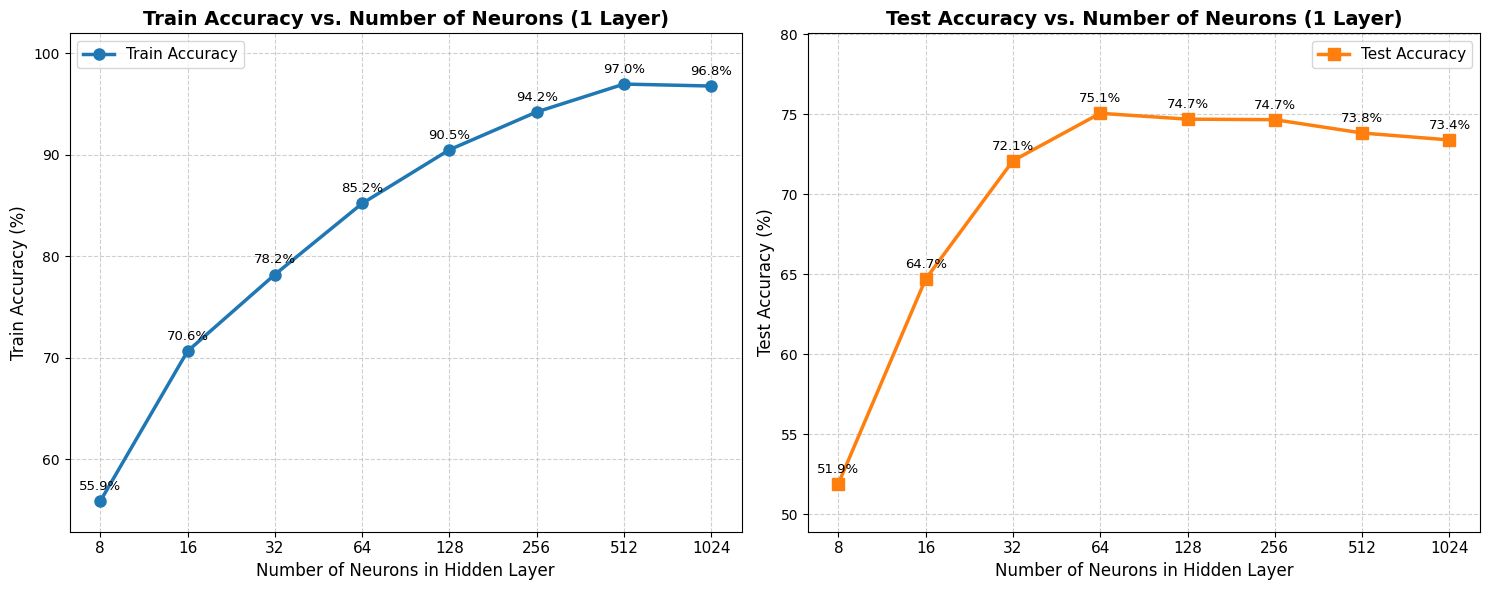

In [4]:
# Create a 1x2 grid for Train Accuracy and Test Accuracy plots
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))

# X-axis positions (equally spaced for powers of 2)
x_positions = np.arange(len(neuron_sizes))
x_labels = [str(n) for n in neuron_sizes]

# --- Plot 1: Train Accuracy vs Number of Neurons ---
axes[0].plot(x_positions, train_accuracies, marker='o', color='#1f77b4', linewidth=2.5, markersize=8, label='Train Accuracy')
axes[0].set_title('Train Accuracy vs. Number of Neurons (1 Layer)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Number of Neurons in Hidden Layer', fontsize=12)
axes[0].set_ylabel('Train Accuracy (%)', fontsize=12)
axes[0].set_xticks(x_positions)
axes[0].set_xticklabels(x_labels, fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(fontsize=11)

# Annotate values on Plot 1
for x, y in zip(x_positions, train_accuracies):
    axes[0].annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0, 8), ha='center', fontsize=9.5)

# --- Plot 2: Test Accuracy vs Number of Neurons ---
axes[1].plot(x_positions, test_accuracies, marker='s', color='#ff7f0e', linewidth=2.5, markersize=8, label='Test Accuracy')
axes[1].set_title('Test Accuracy vs. Number of Neurons (1 Layer)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Number of Neurons in Hidden Layer', fontsize=12)
axes[1].set_ylabel('Test Accuracy (%)', fontsize=12)
axes[1].set_xticks(x_positions)
axes[1].set_xticklabels(x_labels, fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend(fontsize=11)

# Annotate values on Plot 2
for x, y in zip(x_positions, test_accuracies):
    axes[1].annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0, 8), ha='center', fontsize=9.5)

# Adjust y-limits slightly to fit annotations nicely
axes[0].set_ylim(min(train_accuracies) - 3, max(train_accuracies) + 5)
axes[1].set_ylim(min(test_accuracies) - 3, max(test_accuracies) + 5)

plt.tight_layout()
plt.show()